# Adult Income Classification

This notebook downloads the UCI Adult dataset, removes duplicate records, performs a stratified train-test split, trains five classifiers, and saves the metrics, comparison chart, test data, and fitted pipelines.

## Problem statement

The objective of this project is to build and compare supervised classification models that predict whether an individual's annual income is greater than $50,000 or less than or equal to $50,000. This is a binary classification problem. The five required models are evaluated on the same held-out test set using Accuracy, AUC, Precision, Recall, F1-score, and Matthews Correlation Coefficient (MCC).

The assignment evaluates both overall correctness and positive-class detection. Accuracy alone is not sufficient because the income classes are imbalanced, so F1 and MCC are also used to assess balanced classification performance.

## Dataset description

| Item | Description |
|---|---|
| Dataset | UCI Adult (Census Income) dataset |
| Source | UCI Machine Learning Repository |
| Problem type | Binary classification |
| Target variable | `income`: `<=50K` or `>50K`; encoded as 0 or 1 |
| Predictors | 14 demographic and employment attributes |
| Predictor types | 6 numerical and 8 categorical features |
| Instances | 48,842 combined records before duplicate removal |
| Missing values | Represented by `?`, loaded as `NaN`, and median/most-frequent-imputed |
| Class imbalance | Examined below through counts, percentages, and a majority-to-minority ratio |
| Preprocessing | Median imputation, most-frequent imputation, one-hot encoding, standard scaling, duplicate removal, and stratified 80:20 splitting |

The dataset was selected because it is publicly available, contains more than the 1,000 minimum instances, contains at least 12 features, includes mixed numerical/categorical data and missing values, and has a sufficiently imbalanced target for meaningful model comparison.

## Dataset choice

**Why this dataset was selected:** The UCI Adult Census Income dataset is a public, well-known binary classification dataset. It has 14 predictor features and more than 48,000 combined records, satisfying the minimum requirements of at least 12 features and 1,000 instances. It is also suitable for demonstrating missing-value handling, duplicate removal, mixed-type preprocessing, class-imbalance handling, and model comparison.

**Target variable:** `income`, with the classes `<=50K` and `>50K`. It is converted to a binary target where `<=50K = 0` and `>50K = 1`.

**Feature types:** The predictors contain six numerical features (such as `age`, `fnlwgt`, `education_num`, `capital_gain`, `capital_loss`, and `hours_per_week`) and eight categorical features (such as `workclass`, `education`, `marital_status`, `occupation`, `relationship`, `race`, `sex`, and `native_country`).

**Missing values:** Missing entries are represented by `?` and are loaded as `NaN`. Numerical values will be median-imputed and categorical values will be most-frequent-imputed, using statistics learned only from the training fold.

**Class imbalance:** The class distribution is examined below. The split uses stratification so the minority and majority class proportions are maintained in both subsets.

In [5]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

In [6]:
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "src" else cwd
DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs"

for folder in (DATA_DIR, MODEL_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country",
    "income",
]
TRAIN_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
TEST_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

print(f"Project root: {ROOT}")

Project root: /home/s2026ct05052/Downloads


## Download and load the dataset

In [8]:
def download_dataset():
    """Download and combine the original UCI train and test files."""
    train_path = DATA_DIR / "adult.data"
    test_path = DATA_DIR / "adult.test"

    for url, path in ((TRAIN_URL, train_path), (TEST_URL, test_path)):
        if not path.exists():
            print(f"Downloading {path.name} ...")
            urllib.request.urlretrieve(url, path)

    train_df = pd.read_csv(
        train_path,
        names=COLUMNS,
        skipinitialspace=True,
        na_values="?",
        skip_blank_lines=True,
    )
    test_df = pd.read_csv(
        test_path,
        names=COLUMNS,
        skipinitialspace=True,
        na_values="?",
        skiprows=1,
        comment="|",
        skip_blank_lines=True,
    )

    df = pd.concat([train_df, test_df], ignore_index=True)
    df["income"] = df["income"].astype(str).str.strip().str.rstrip(".")
    df["income"] = df["income"].str.replace(".", "", regex=False)
    df = df[df["income"].isin(["<=50K", ">50K"])].copy()
    return df


df = download_dataset()
print("Dataset shape before duplicate removal:", df.shape)
print("Missing values by column:\n", df.isna().sum())
print("Duplicate rows:", int(df.duplicated().sum()))

Dataset shape before duplicate removal: (48842, 15)
Missing values by column:
 age                  0
workclass         2799
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     857
income               0
dtype: int64
Duplicate rows: 52


Feature data types:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
feature_type,int64,object,int64,object,int64,object,object,object,object,object,int64,int64,int64,object


,Count,Percentage
income,,
<=50K,37155,76.07
>50K,11687,23.93


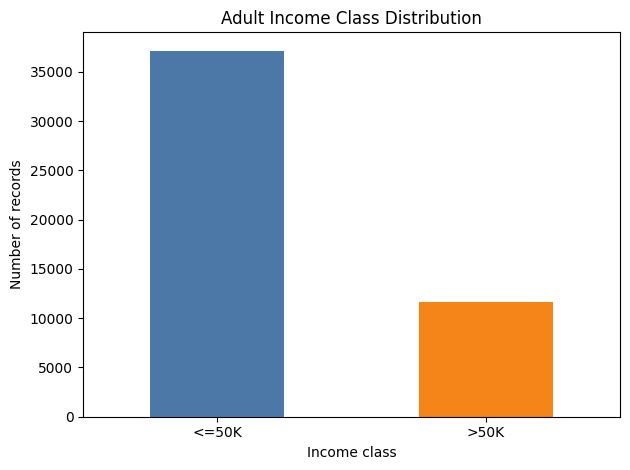

Majority-to-minority count ratio: 3.18:1


In [9]:
feature_df = df.drop(columns="income")
feature_types = feature_df.dtypes.astype(str)
print("Feature data types:")
display(pd.DataFrame({"feature_type": feature_types}).T)

class_counts = df["income"].value_counts().sort_index()
class_percentages = df["income"].value_counts(normalize=True).sort_index() * 100
imbalance_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2),
})
display(imbalance_summary)

imbalance_summary["Count"].plot(kind="bar", color=["#4C78A8", "#F58518"])
plt.title("Adult Income Class Distribution")
plt.xlabel("Income class")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Majority-to-minority count ratio: {imbalance_ratio:.2f}:1")

## Clean the data and create the train-test split

###  Preprocessing requirements
- Missing values are identified with `isna()` and loaded as `NaN` from `?` entries.
- Numerical missing values are median-imputed; categorical missing values are most-frequent-imputed.
- Duplicate records are identified with `duplicated()` and removed before the train-test split.
- Categorical features are one-hot encoded with unknown-category handling.
- Numerical features are standardized using `StandardScaler`.
- The dataset is divided 80:20 using `train_test_split` with `stratify=y`.
- `RANDOM_STATE = 42` provides reproducibility.
- Every imputer, scaler, encoder, and model is connected in a `Pipeline`, so preprocessing is fitted only on the training subset.

In [11]:
# Remove duplicate records before splitting.
df = df.drop_duplicates().reset_index(drop=True)
print("Dataset shape after duplicate removal:", df.shape)
print("\nIncome class distribution:\n", df["income"].value_counts())

X = df.drop(columns="income")
y = (df["income"] == ">50K").astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"\nTrain records: {len(X_train)} | Test records: {len(X_test)}")
print("Train class proportions:\n", y_train.value_counts(normalize=True))
print("Test class proportions:\n", y_test.value_counts(normalize=True))

Dataset shape after duplicate removal: (48790, 15)

Income class distribution:
 income
<=50K    37109
>50K     11681
Name: count, dtype: int64

Train records: 39032 | Test records: 9758
Train class proportions:
 income
0    0.760581
1    0.239419
Name: proportion, dtype: float64
Test class proportions:
 income
0    0.760607
1    0.239393
Name: proportion, dtype: float64


## Models used

### Five required classification models

All five models are trained on the same preprocessed, stratified 80:20 train-test split. The following configurations preserve the assignment requirements:

1. **Logistic Regression:** `max_iter=1000`, `class_weight='balanced'`, random seed 42.
2. **Decision Tree:** maximum depth 12, minimum split size 10, balanced class weights, random seed 42.
3. **K-Nearest Neighbors:** 7 neighbours.
4. **Gaussian Naive Bayes:** Gaussian likelihood for the standardized and one-hot encoded features.
5. **Random Forest:** 200 trees, maximum depth 16, minimum split size 5, balanced subsample weights, random seed 42.

### Evaluation metrics for every model

Each model is evaluated using Accuracy, AUC, Precision, Recall, F1-score, and MCC. AUC uses the positive-class probability, while the other metrics use the predicted class labels.

**Evaluation requirements:** Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes, and Random Forest. Balanced class weights are used where supported to account for class imbalance. Accuracy, AUC, Precision, Recall, F1, and MCC are calculated for every model using the held-out test set.

In [13]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=16,
        min_samples_split=5,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

In [14]:
results = []
fitted_models = {}

for name, estimator in models.items():
    print(f"\nTraining {name} ...")

    # Use dense one-hot output so GaussianNB also receives a supported matrix.
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    prep = ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", encoder),
        ]), categorical_features),
    ])

    pipe = Pipeline(steps=[
        ("preprocessing", prep),
        ("classifier", estimator),
    ])
    pipe.fit(X_train, y_train)

    predictions = pipe.predict(X_test)
    probabilities = pipe.predict_proba(X_test)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(y_test, probabilities),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predictions),
    }
    results.append(row)
    fitted_models[name] = pipe

    safe_name = name.lower().replace(" ", "_")
    joblib.dump(pipe, MODEL_DIR / f"{safe_name}.joblib")
    print(pd.Series(row).to_string())


Training Logistic Regression ...
Model        Logistic Regression
Accuracy                0.808157
AUC                     0.907999
Precision               0.565984
Recall                  0.851884
F1                      0.680109
MCC                     0.574421

Training Decision Tree ...
Model        Decision Tree
Accuracy          0.802419
AUC               0.890312
Precision          0.55673
Recall            0.857021
F1                0.674983
MCC                0.56811

Training KNN ...
Model             KNN
Accuracy     0.840541
AUC          0.878761
Precision    0.686246
Recall       0.615154
F1           0.648758
MCC           0.54738

Training Naive Bayes ...
Model        Naive Bayes
Accuracy        0.598996
AUC             0.817373
Precision       0.367234
Recall          0.933647
F1               0.52713
MCC             0.373606

Training Random Forest ...
Model        Random Forest
Accuracy          0.813794
AUC                0.91625
Precision         0.574462
Recall   

## 4. Comparison table, graph representation, observations, and saved outputs

In [16]:
metrics = pd.DataFrame(results).set_index("Model")
metrics.to_csv(OUTPUT_DIR / "metrics.csv")
metrics

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.808157,0.907999,0.565984,0.851884,0.680109,0.574421
Decision Tree,0.802419,0.890312,0.556730,0.857021,0.674983,0.568110
KNN,0.840541,0.878761,0.686246,0.615154,0.648758,0.547380
Naive Bayes,0.598996,0.817373,0.367234,0.933647,0.527130,0.373606
Random Forest,0.813794,0.916250,0.574462,0.857021,0.687854,0.585277


### Comparison Table

The table above reports all five models and all six required metrics. It is also saved in `outputs/metrics.csv` for use in the report.

### Graph Representation

The bar chart below visualizes Accuracy, AUC, Precision, Recall, F1, and MCC for all five models.

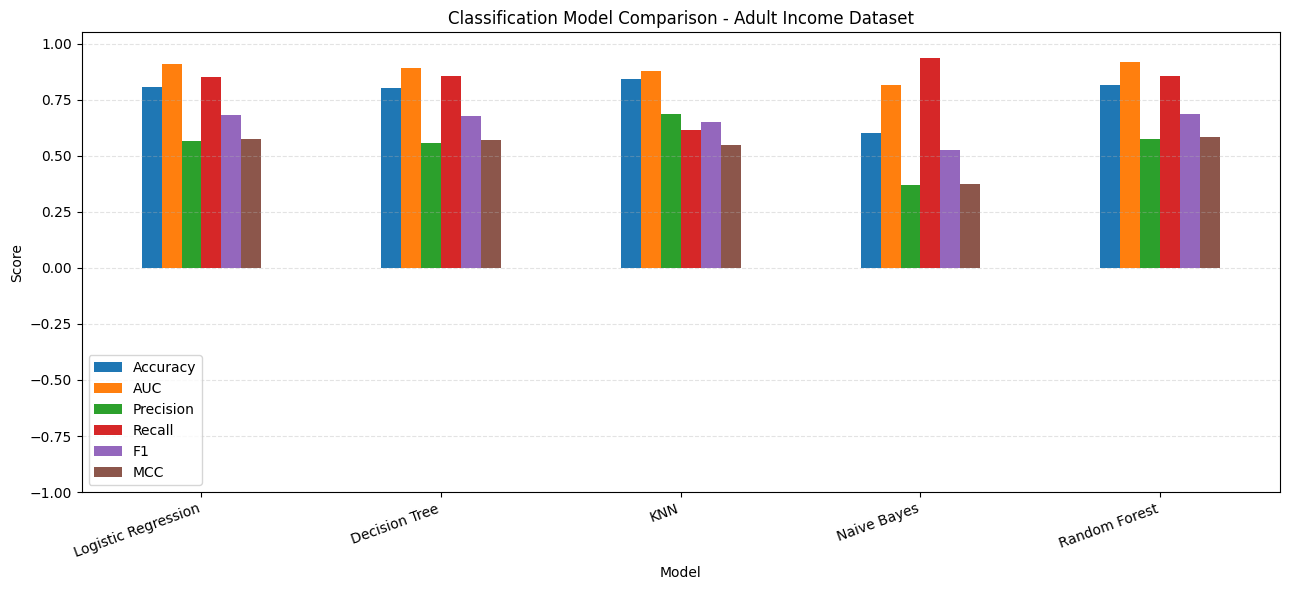


Metrics saved to outputs/metrics.csv
Comparison graph saved to outputs/model_comparison.png
Held-out test data saved to test_data.csv
Saved model pipelines to models/
Overall winner by F1 score: Random Forest


In [19]:
ax = metrics.plot(kind="bar", figsize=(13, 6), ylim=(-1, 1.05))
ax.set_title("Classification Model Comparison - Adult Income Dataset")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison.png", dpi=180)
plt.show()

test_export = X_test.copy()
test_export["income_actual"] = np.where(y_test == 1, ">50K", "<=50K")
test_export.to_csv(ROOT / "test_data.csv", index=False)

winner = metrics["F1"].idxmax()
print("\nMetrics saved to outputs/metrics.csv")
print("Comparison graph saved to outputs/model_comparison.png")
print("Held-out test data saved to test_data.csv")
print("Saved model pipelines to models/")
print(f"Overall winner by F1 score: {winner}")

## Observations on model performance

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Accuracy is 0.8082 and AUC is 0.9080, showing good discrimination. Recall is strong at 0.8519, but Precision is lower at 0.5660, indicating relatively more false positives for the `>50K` class. F1 is 0.6801 and MCC is 0.5744. |
| Decision Tree | Accuracy is 0.8023 and Recall is 0.8574, so it identifies many high-income records. However, Precision is 0.5565 and AUC is 0.8900, while F1 (0.6750) and MCC (0.5682) are lower than Random Forest. |
| K-Nearest Neighbors | KNN has the highest Accuracy (0.8405) and a strong Precision (0.6862), but Recall is only 0.6152. It is consequently weaker on F1 (0.6488) and MCC (0.5474), and misses more positive `>50K` cases. |
| Gaussian Naive Bayes | Naive Bayes gives the highest Recall (0.9336), which means it finds almost all positive cases, but it has poor Accuracy (0.5990), Precision (0.3672), F1 (0.5271), and MCC (0.3736). It produces too many false positives and is not the strongest overall model. |
| Random Forest | Random Forest provides the highest AUC (0.9159), F1 (0.6861), and MCC (0.5827), together with strong Recall (0.8545). It gives the best overall balance between identifying `>50K` records and limiting false positives in this run. |
| Overall winner | Random Forest is the overall winner when selecting by F1 score. It also achieves the best AUC and MCC in the current output, making it the most balanced choice for this imbalanced binary classification problem. |

Although KNN has the highest Accuracy, Random Forest is preferred because F1 and MCC account better for the imbalanced `>50K` minority class. Naive Bayes demonstrates the value of considering multiple metrics: very high Recall is accompanied by low Precision and MCC.